In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)

In [3]:
leaderboard_path = Path.cwd().parent / "results" / "leaderboard.csv"
df = pd.read_csv(leaderboard_path, parse_dates=["timestamp"])
df.head()

,run_dir,name,timestamp,task,seed,duration_s,status,error,data.datasets,data.n_images,data.test_size,data.stratify,transform.img_size,transform.reinhard,transform.reinhard_samples,transform.clahe,transform.clahe_clip_limit,transform.clahe_grid_size,transform.jpeg,transform.jpeg_quality,transform.p_rotation,transform.p_brightness,transform.p_contrast,transform.brightness_delta,transform.contrast_delta,model.name,loss.name,loss.beta,loss.gamma,loss.lambda_cost,optim.name,optim.lr,optim.weight_decay,scheduler.name,scheduler.patience,scheduler.lr_min,scheduler.step_gamma,train.nb_epoch,train.batch_size,train.validation,train.val_size,train.cross_val_folds,train.early_stopping_patience,train.device,output.root,output.save_checkpoint,output.save_figures,test_loss,test_f1_macro,test_mcc,min_critical_recall,val_f1_macro,transform.p_flip,test_acc,grid.max_combinations,train.sampler,verbose,train.sampler_alpha,train.num_workers,test_top3_acc,test_top3_f1,train.grad_clip_norm,val_min_critical_recall,val_loss,val_mcc,val_top3_acc,val_top3_f1,val_acc,transform.p_blur,transform.blur_kernel_size,transform.blur_sigma_min,transform.blur_sigma_max,loss.extra_weight.Blast,loss.extra_weight.Promyelocyte,loss.extra_weight.IG,loss.extra_weight.Erythroblast,model.architecture,transform.norm_stats,model.transfer,loss.label_smoothing,loss.cost_matrix
0,results/runs/3f23aa17,NaN,2026-09-02 20:31:14,type,0,72.9,ok,NaN,"['barcelona', 'munich']",2000,0.15,type_dataset,"[224, 224]",True,500,True,2.0,8,True,35,0.9,0.5,0.5,0.15,0.15,baseline,cross_entropy,0.9999,2.0,1.0,adam,0.01,0.0,none,3,0.0,0.1,3,32,holdout,0.15,3,0,auto,results,True,True,1.897938,0.315757,0.247443,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,results/runs/f5389757,NaN,2026-09-02 21:26:51,dataset,0,160.8,ok,NaN,"['barcelona', 'munich']",5000,0.15,dataset,"[224, 224]",True,500,True,2.0,8,True,35,0.9,0.5,0.5,0.15,0.15,baseline,cross_entropy,0.9999,2.0,1.0,adam,0.01,0.0,none,3,0.0,0.1,3,64,holdout,0.15,3,0,auto,results,False,False,0.100693,0.984000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,results/runs/aa697716,NaN,2026-09-02 21:28:43,dataset,0,73.8,ok,NaN,"['barcelona', 'munich']",2000,0.15,dataset,"[224, 224]",True,500,True,2.0,8,True,35,0.9,0.5,0.5,0.15,0.15,baseline,cross_entropy,0.9999,2.0,1.0,adam,0.01,0.0,none,3,0.0,0.1,3,64,holdout,0.15,3,0,auto,results,False,False,0.693197,0.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,results/runs/31e76e43,NaN,2026-09-02 21:34:01,dataset,0,160.9,ok,NaN,"['barcelona', 'munich']",5000,0.15,dataset,"[224, 224]",True,500,True,2.0,8,True,30,0.9,0.5,0.5,0.15,0.15,baseline,cross_entropy,0.9999,2.0,1.0,adam,0.01,0.0,none,3,0.0,0.1,3,64,holdout,0.15,3,0,auto,results,False,False,0.034396,0.994667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,results/runs/3862ba90,NaN,2026-09-02 22:30:43,dataset,0,153.1,ok,NaN,"['barcelona', 'munich']",5000,0.15,dataset,"[224, 224]",True,500,True,1.0,8,True,25,0.0,0.0,0.0,0.15,0.15,baseline,cross_entropy,0.9999,2.0,1.0,adam,0.01,0.0,none,3,0.0,0.1,3,64,holdout,0.15,3,0,auto,results,False,False,0.032214,NaN,NaN,NaN,NaN,0.0,0.994667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
columns = [
    "timestamp",
    "test_acc",
    "transform.reinhard",
    "transform.clahe",
    "transform.jpeg_quality",
    "transform.p_brightness",
    "transform.p_contrast",
    "transform.brightness_delta",
    "transform.contrast_delta",
]
df_dataset = df[(df["task"] == "dataset") & (df["test_acc"].notna())][columns]
df_dataset["test_acc_ok"] = df_dataset["test_acc"] < 0.7
print(len(df_dataset[df_dataset["test_acc_ok"]]), "configurations with test_acc < 0.7")
df_dataset[df_dataset["test_acc_ok"]]

21 configurations with test_acc < 0.7


,timestamp,test_acc,transform.reinhard,transform.clahe,transform.jpeg_quality,transform.p_brightness,transform.p_contrast,transform.brightness_delta,transform.contrast_delta,test_acc_ok
26,2026-09-02 23:05:05,0.5,True,True,25,0.50,0.50,0.15,0.15,True
28,2026-09-02 23:08:30,0.5,True,True,30,0.50,0.50,0.15,0.15,True
29,2026-09-02 23:09:52,0.5,True,True,30,0.50,0.50,0.15,0.15,True
30,2026-09-02 23:11:13,0.5,True,True,30,0.50,0.50,0.15,0.15,True
34,2026-09-02 23:18:04,0.5,True,True,30,0.50,0.50,0.15,0.30,True
35,2026-09-02 23:19:57,0.5,True,True,30,0.50,0.50,0.15,0.00,True
73,2026-09-03 02:03:30,0.5,True,False,50,0.25,0.00,0.20,0.20,True
77,2026-09-03 02:05:46,0.5,True,True,40,0.50,0.00,0.20,0.10,True
83,2026-09-03 02:46:24,0.5,True,False,25,0.50,0.50,0.15,0.20,True
101,2026-09-03 02:59:30,0.5,True,False,30,0.50,0.25,0.20,0.20,True


In [ ]:
for c in (c for c in df_dataset.columns if c not in ["timestamp", "test_acc", "test_acc_ok"]):
    print(
        f"Column {c} : {df_dataset[df_dataset['test_acc_ok']][c].nunique()} valeurs uniques: {df_dataset[df_dataset['test_acc_ok']][c].unique()}"
    )


Column transform.reinhard : 1 valeurs uniques: [ True]
Column transform.clahe : 2 valeurs uniques: [ True False]
Column transform.jpeg_quality : 4 valeurs uniques: [25 30 50 40]
Column transform.p_brightness : 2 valeurs uniques: [0.5  0.25]
Column transform.p_contrast : 3 valeurs uniques: [0.5  0.   0.25]
Column transform.brightness_delta : 3 valeurs uniques: [0.15 0.2  0.1 ]
Column transform.contrast_delta : 5 valeurs uniques: [0.15 0.3  0.   0.2  0.1 ]


In [ ]:
df_dataset[df_dataset["test_acc_ok"]]["transform.jpeg_quality"].value_counts()

transform.jpeg_quality
30    11
25     5
40     3
50     2
Name: count, dtype: int64

In [ ]:
df_dataset[df_dataset["test_acc_ok"]]["transform.brightness_delta"].value_counts()

transform.brightness_delta
0.15    9
0.20    7
0.10    5
Name: count, dtype: int64

In [ ]:
df_dataset[df_dataset["test_acc_ok"]]["transform.p_brightness"].value_counts()

transform.p_brightness
0.50    17
0.25     4
Name: count, dtype: int64

In [ ]:
df_dataset[df_dataset["test_acc_ok"]]["transform.clahe"].value_counts()

transform.clahe
True     17
False     4
Name: count, dtype: int64

In [ ]:
df_dataset[df_dataset["test_acc_ok"]]["transform.p_contrast"].value_counts()

transform.p_contrast
0.50    11
0.00     6
0.25     4
Name: count, dtype: int64

In [ ]:
df_dataset[df_dataset["test_acc_ok"]]["transform.contrast_delta"].value_counts()

transform.contrast_delta
0.15    10
0.20     6
0.10     3
0.30     1
0.00     1
Name: count, dtype: int64

In [ ]:
df_dataset[
    (df_dataset["transform.jpeg_quality"] == 30)
    & (df_dataset["transform.brightness_delta"] == 0.20)
    & (df_dataset["transform.p_brightness"] == 0.5)
    & (df_dataset["transform.clahe"])
    & (df_dataset["transform.p_contrast"] == 0.5)
    & (df_dataset["transform.contrast_delta"] == 0.15)
]

,timestamp,test_acc,transform.reinhard,transform.clahe,transform.jpeg_quality,transform.p_brightness,transform.p_contrast,transform.brightness_delta,transform.contrast_delta,test_acc_ok


In [ ]:
run_name = "grid_citicality_loss_2"


def refresh_grid(run_name):
    df = pd.read_csv(leaderboard_path, parse_dates=["timestamp"])
    df_run = df[df.name == run_name]
    df_run["transform.brightness_delta"] = df_run.apply(
        lambda row: row["transform.brightness_delta"] if row["transform.p_brightness"] > 0 else 0,
        axis=1,
    )
    df_run["transform.contrast_delta"] = df_run.apply(
        lambda row: row["transform.contrast_delta"] if row["transform.p_contrast"] > 0 else 0,
        axis=1,
    )
    df_run_grid = df_run.loc[:, df_run.nunique(dropna=False) > 1]
    return df, df_run_grid


df, df_run_grid = refresh_grid(run_name)


def show_grid_results(df_run_grid, by="val_f1_macro", ascending=False, n_best=25):
    display(
        df_run_grid.sort_values(by=by, ascending=ascending)
        # .sort_values(by="timestamp")
        .sort_index(axis=1)
        # .head(n_best)
    )
    print(len(df_run_grid))


df_run_grid["f1_recall"] = df_run_grid.apply(
    lambda row: (row.val_f1_macro + row.val_min_critical_recall) / 2.0, axis=1
)
show_grid_results(df_run_grid, by="f1_recall")
# show_grid_results(df_run_grid, by="val_acc", ascending=True)
show_grid_results(df_run_grid)

,duration_s,f1_recall,loss.beta,loss.gamma,loss.lambda_cost,run_dir,timestamp,val_f1_macro,val_loss,val_mcc,val_min_critical_recall
1053,245.6,0.938826,0.9999,2.0,0.0,results/runs/dc653454,2026-09-10 11:52:42,0.919073,0.069841,0.879247,0.958580
1025,249.1,0.938823,0.9900,3.0,0.0,results/runs/376cbdd3,2026-09-10 09:54:13,0.913150,0.049906,0.870185,0.964497
1057,252.2,0.938232,0.9999,3.0,0.0,results/runs/fdef4d48,2026-09-10 12:09:15,0.919856,0.043388,0.880115,0.956608
1041,251.8,0.937420,0.9990,3.0,0.0,results/runs/fb42b877,2026-09-10 11:02:31,0.914288,0.050731,0.872362,0.960552
1029,263.1,0.935076,0.9990,0.0,0.0,results/runs/900655fd,2026-09-10 10:11:40,0.917490,0.221634,0.876626,0.952663
1032,258.3,0.934736,0.9990,0.0,2.0,results/runs/2fb68465,2026-09-10 10:24:42,0.904975,0.744580,0.859440,0.964497
1021,250.4,0.934673,0.9900,2.0,0.0,results/runs/0bca4dd2,2026-09-10 09:37:53,0.916683,0.077208,0.876444,0.952663
1045,252.2,0.933214,0.9999,0.0,0.0,results/runs/7971679c,2026-09-10 11:19:16,0.913766,0.241818,0.872923,0.952663
1037,241.3,0.932135,0.9990,2.0,0.0,results/runs/edb0127c,2026-09-10 10:45:51,0.909635,0.077398,0.866149,0.954635
1026,253.3,0.932016,0.9900,3.0,0.5,results/runs/68e8a2af,2026-09-10 09:58:27,0.897563,0.256196,0.849628,0.966469


49


,duration_s,f1_recall,loss.beta,loss.gamma,loss.lambda_cost,run_dir,timestamp,val_f1_macro,val_loss,val_mcc,val_min_critical_recall
1057,252.2,0.938232,0.9999,3.0,0.0,results/runs/fdef4d48,2026-09-10 12:09:15,0.919856,0.043388,0.880115,0.956608
1053,245.6,0.938826,0.9999,2.0,0.0,results/runs/dc653454,2026-09-10 11:52:42,0.919073,0.069841,0.879247,0.958580
1033,262.4,0.928178,0.9990,1.0,0.0,results/runs/b49536f3,2026-09-10 10:29:04,0.917500,0.124415,0.877809,0.938856
1029,263.1,0.935076,0.9990,0.0,0.0,results/runs/900655fd,2026-09-10 10:11:40,0.917490,0.221634,0.876626,0.952663
1021,250.4,0.934673,0.9900,2.0,0.0,results/runs/0bca4dd2,2026-09-10 09:37:53,0.916683,0.077208,0.876444,0.952663
1014,241.0,0.919864,0.9900,0.0,0.5,results/runs/1b053f61,2026-09-10 09:09:14,0.916651,0.397331,0.875415,0.923077
1030,261.3,0.920452,0.9990,0.0,0.5,results/runs/4b8fa90b,2026-09-10 10:16:01,0.915856,0.389789,0.874645,0.925049
1035,250.3,0.929116,0.9990,1.0,1.0,results/runs/8b9c2a3a,2026-09-10 10:37:30,0.915430,0.411680,0.874204,0.942801
1041,251.8,0.937420,0.9990,3.0,0.0,results/runs/fb42b877,2026-09-10 11:02:31,0.914288,0.050731,0.872362,0.960552
1045,252.2,0.933214,0.9999,0.0,0.0,results/runs/7971679c,2026-09-10 11:19:16,0.913766,0.241818,0.872923,0.952663


49


In [9]:
df_run_grid.groupby("loss.gamma")[[c for c in df_run_grid.columns if c.startswith("val_")]].std()

,val_f1_macro,val_min_critical_recall,val_loss,val_mcc
loss.gamma,,,,
0.0,0.009475,0.021794,0.155472,0.012632
1.0,0.009475,0.021794,0.155472,0.012632
2.0,0.009185,0.023324,0.159509,0.012405
3.0,0.008440,0.024475,0.160182,0.011175
5.0,NaN,NaN,NaN,NaN


In [9]:
df_run = df[df.name == run_name]
df_run

,run_dir,name,timestamp,task,seed,duration_s,status,error,data.datasets,data.n_images,data.test_size,data.stratify,transform.img_size,transform.reinhard,transform.reinhard_samples,transform.clahe,transform.clahe_clip_limit,transform.clahe_grid_size,transform.jpeg,transform.jpeg_quality,transform.p_rotation,transform.p_brightness,transform.p_contrast,transform.brightness_delta,transform.contrast_delta,model.name,loss.name,loss.beta,loss.gamma,loss.lambda_cost,optim.name,optim.lr,optim.weight_decay,scheduler.name,scheduler.patience,scheduler.lr_min,scheduler.step_gamma,train.nb_epoch,train.batch_size,train.validation,train.val_size,train.cross_val_folds,train.early_stopping_patience,train.device,output.root,output.save_checkpoint,output.save_figures,test_loss,test_f1_macro,test_mcc,min_critical_recall,val_f1_macro,transform.p_flip,test_acc,grid.max_combinations,train.sampler,verbose,train.sampler_alpha,train.num_workers,test_top3_acc,test_top3_f1,train.grad_clip_norm,val_min_critical_recall,val_loss,val_mcc,val_top3_acc,val_top3_f1,val_acc,transform.p_blur,transform.blur_kernel_size,transform.blur_sigma_min,transform.blur_sigma_max,loss.extra_weight.Blast,loss.extra_weight.Promyelocyte,loss.extra_weight.IG,loss.extra_weight.Erythroblast,model.architecture,transform.norm_stats,model.transfer,loss.label_smoothing,loss.cost_matrix
1012,results/runs/beae8b80,grid_citicality_loss_2,2026-09-10 09:01:06,criticality,0,237.6,ok,NaN,"['barcelona', 'munich']",15000,0.15,criticality,"[224, 224]",True,500,True,2.0,8,True,60,0.5,0.5,0.5,0.25,0.15,baseline,clinical,0.000,0.0,0.0,adam,0.001,0.0,none,3,0.0,0.1,10,64,holdout,0.15,3,10,auto,results,False,False,NaN,NaN,NaN,NaN,0.910588,0.5,NaN,NaN,none,True,1.0,10.0,NaN,NaN,1.0,0.895464,0.234741,0.866802,NaN,NaN,NaN,0.0,5.0,0.1,2.0,NaN,NaN,NaN,NaN,NaN,dataset,NaN,0.0,NaN
1013,results/runs/6f43ba7d,grid_citicality_loss_2,2026-09-10 09:05:13,criticality,0,246.5,ok,NaN,"['barcelona', 'munich']",15000,0.15,criticality,"[224, 224]",True,500,True,2.0,8,True,60,0.5,0.5,0.5,0.25,0.15,baseline,clinical,0.990,0.0,0.0,adam,0.001,0.0,none,3,0.0,0.1,10,64,holdout,0.15,3,10,auto,results,False,False,NaN,NaN,NaN,NaN,0.910588,0.5,NaN,NaN,none,True,1.0,10.0,NaN,NaN,1.0,0.895464,0.234741,0.866802,NaN,NaN,NaN,0.0,5.0,0.1,2.0,NaN,NaN,NaN,NaN,NaN,dataset,NaN,0.0,NaN
1014,results/runs/1b053f61,grid_citicality_loss_2,2026-09-10 09:09:14,criticality,0,241.0,ok,NaN,"['barcelona', 'munich']",15000,0.15,criticality,"[224, 224]",True,500,True,2.0,8,True,60,0.5,0.5,0.5,0.25,0.15,baseline,clinical,0.990,0.0,0.5,adam,0.001,0.0,none,3,0.0,0.1,10,64,holdout,0.15,3,10,auto,results,False,False,NaN,NaN,NaN,NaN,0.916651,0.5,NaN,NaN,none,True,1.0,10.0,NaN,NaN,1.0,0.923077,0.397331,0.875415,NaN,NaN,NaN,0.0,5.0,0.1,2.0,NaN,NaN,NaN,NaN,NaN,dataset,NaN,0.0,NaN
1015,results/runs/e0b9f4fb,grid_citicality_loss_2,2026-09-10 09:13:20,criticality,0,245.6,ok,NaN,"['barcelona', 'munich']",15000,0.15,criticality,"[224, 224]",True,500,True,2.0,8,True,60,0.5,0.5,0.5,0.25,0.15,baseline,clinical,0.990,0.0,1.0,adam,0.001,0.0,none,3,0.0,0.1,10,64,holdout,0.15,3,10,auto,results,False,False,NaN,NaN,NaN,NaN,0.884762,0.5,NaN,NaN,none,True,1.0,10.0,NaN,NaN,1.0,0.960552,0.534319,0.833203,NaN,NaN,NaN,0.0,5.0,0.1,2.0,NaN,NaN,NaN,NaN,NaN,dataset,NaN,0.0,NaN
1016,results/runs/bc9878fd,grid_citicality_loss_2,2026-09-10 09:17:20,criticality,0,240.6,ok,NaN,"['barcelona', 'munich']",15000,0.15,criticality,"[224, 224]",True,500,True,2.0,8,True,60,0.5,0.5,0.5,0.25,0.15,baseline,clinical,0.990,0.0,2.0,adam,0.001,0.0,none,3,0.0,0.1,10,64,holdout,0.15,3,10,auto,results,False,False,NaN,NaN,NaN,NaN,0.882097,0.5,NaN,NaN,none,True,1.0,10.0,NaN,NaN,1.0,0.938856,0.733957,0.829282,NaN,NaN,NaN,0.0,5.0,0.1,2.0,NaN,NaN,NaN,NaN,NaN,dataset,NaN,0.0,NaN
1017,results/runs/0fe13d32,grid_citicality_loss_2,2026-09-10 09:21:23,criticality,0,243.0,ok,NaN,"['barcelona', 'munich']",15000,0.15,criticality,"[224, 224]",True,500,True,2.0,8,True,60,0.5,0.5,0.5,0.25,0.15,baseline,clinical,0.990,1.0,

In [7]:
transform_cols = [c for c in df_run_grid.columns if c.startswith("transform.")]
val_cols = [c for c in df_run_grid.columns if c.startswith("val_")]


def show_grid_results_grouped(transform_cols, val_cols):
    display(
        df_run_grid.melt(
            id_vars=val_cols, value_vars=transform_cols, var_name="param", value_name="value"
        )
        .groupby(["param", "value"], dropna=False)[val_cols]
        .mean()
    )
    for col in transform_cols:
        if df_run_grid[col].nunique(dropna=False) > 1:
            display(df_run_grid.groupby(col, dropna=False)[val_cols].mean())


show_grid_results_grouped(transform_cols, val_cols)


val_f1_macro  val_min_critical_recall  \
param                      value                                          
transform.blur_kernel_size 3.0        0.857378                 0.791850   
                           5.0        0.853548                 0.770611   
                           9.0        0.848874                 0.760421   
                           33.0       0.852857                 0.767619   
transform.blur_sigma_max   2.0        0.852914                 0.785957   
                           4.0        0.854592                 0.768735   
                           8.0        0.851348                 0.767453   
                           100.0      0.852857                 0.767619   
transform.clahe            False      0.853826                 0.773280   
                           True       0.841036                 0.741721   
transform.clahe_clip_limit False      0.853826                 0.773280   
                           2.0        0.857470                 0.602273   
                           4.0        0.839028                 0.769606   
                           8.0        0.841582                 0.704545   
transform.clahe_grid_size  False      0.853826                 0.773280   
                           8.0        0.841036                 0.741721   
transform.contrast_delta   False      0.851830                 0.770402   
                           0.1        0.857293                 0.774421   
                           0.2        0.860777                 0.775957   
                           0.3        0.854923                 0.773674   
transform.jpeg             False      0.852864                 0.770699   
                           True       0.854290                 0.776417   
transform.jpeg_quality     False      0.852864                 0.770699   
                           20         0.842914                 0.756861   
                           30         0.840516                 0.750000   
                           40         0.863890                 0.765759   
                           50         0.875152                 0.839623   
                           60         0.846266                 0.753431   
                           70         0.868635                 0.828741   
transform.p_blur           False      0.852857                 0.767619   
                           0.33       0.852997                 0.763909   
                           0.5        0.855795                 0.780199   
                           0.9        0.851296                 0.777685   
transform.p_contrast       False      0.851830                 0.770402   
                           0.33       0.854801                 0.778897   
                           0.5        0.862439                 0.768357   
                           0.9        0.856219                 0.777806   
transform.p_flip           False      0.848571                 0.760432   
                           0.33       0.853426                 0.781965   
                           0.5        0.860561                 0.786997   
                           0.9        0.850707                 0.758511   
transform.p_rotation       False      0.842114                 0.755146   
                           0.33       0.854652                 0.773541   
                           0.5        0.857198                 0.783212   
                           0.9        0.856223                 0.770176   
transform.reinhard         False      0.853029                 0.772801   
                           True       0.852970                 0.769723   

                                  val_loss   val_mcc  val_top3_acc  \
param                      value                                     
transform.blur_kernel_size 3.0    0.285449  0.852417      0.981682   
                           5.0    0.296650  0.848850      0.981436   
                           9.0    0.302830  0.844058      0.980096   
        

,val_f1_macro,val_min_critical_recall,val_loss,val_mcc,val_top3_acc,val_top3_f1
transform.reinhard,,,,,,
False,0.853029,0.772801,0.297229,0.847276,0.981128,0.979355
True,0.852970,0.769723,0.293723,0.848531,0.980875,0.979016


,val_f1_macro,val_min_critical_recall,val_loss,val_mcc,val_top3_acc,val_top3_f1
transform.clahe,,,,,,
False,0.853826,0.773280,0.295335,0.848770,0.980994,0.979190
True,0.841036,0.741721,0.297115,0.835526,0.981076,0.979085


,val_f1_macro,val_min_critical_recall,val_loss,val_mcc,val_top3_acc,val_top3_f1
transform.clahe_clip_limit,,,,,,
0.0,0.853826,0.773280,0.295335,0.848770,0.980994,0.979190
2.0,0.857470,0.602273,0.250713,0.855922,0.984754,0.983064
4.0,0.839028,0.769606,0.301338,0.833245,0.981058,0.979097
8.0,0.841582,0.704545,0.299916,0.835569,0.979903,0.977725


,val_f1_macro,val_min_critical_recall,val_loss,val_mcc,val_top3_acc,val_top3_f1
transform.clahe_grid_size,,,,,,
0,0.853826,0.773280,0.295335,0.848770,0.980994,0.979190
8,0.841036,0.741721,0.297115,0.835526,0.981076,0.979085


,val_f1_macro,val_min_critical_recall,val_loss,val_mcc,val_top3_acc,val_top3_f1
transform.jpeg,,,,,,
False,0.852864,0.770699,0.294518,0.847745,0.981137,0.979324
True,0.854290,0.776417,0.304375,0.849526,0.979684,0.977829


... (4 outputs left out)

,val_f1_macro,val_min_critical_recall,val_loss,val_mcc,val_top3_acc,val_top3_f1
transform.p_flip,,,,,,
0.00,0.848571,0.760432,0.323546,0.842466,0.980017,0.978341
0.33,0.853426,0.781965,0.284436,0.848405,0.981894,0.980065
0.50,0.860561,0.786997,0.272968,0.856170,0.982233,0.980426
0.90,0.850707,0.758511,0.292416,0.846196,0.980129,0.978127


,val_f1_macro,val_min_critical_recall,val_loss,val_mcc,val_top3_acc,val_top3_f1
transform.p_blur,,,,,,
0.00,0.852857,0.767619,0.295400,0.847306,0.980905,0.979144
0.33,0.852997,0.763909,0.297930,0.848964,0.981214,0.979151
0.50,0.855795,0.780199,0.281270,0.850696,0.982339,0.980525
0.90,0.851296,0.777685,0.302899,0.845929,0.980018,0.978350


,val_f1_macro,val_min_critical_recall,val_loss,val_mcc,val_top3_acc,val_top3_f1
transform.blur_kernel_size,,,,,,
3.0,0.857378,0.791850,0.285449,0.852417,0.981682,0.979853
5.0,0.853548,0.770611,0.296650,0.848850,0.981436,0.979709
9.0,0.848874,0.760421,0.302830,0.844058,0.980096,0.978099
33.0,0.852857,0.767619,0.295400,0.847306,0.980905,0.979144


,val_f1_macro,val_min_critical_recall,val_loss,val_mcc,val_top3_acc,val_top3_f1
transform.blur_sigma_max,,,,,,
2.0,0.852914,0.785957,0.295803,0.846819,0.981420,0.979609
4.0,0.854592,0.768735,0.294274,0.850736,0.980804,0.978832
8.0,0.851348,0.767453,0.296686,0.846518,0.981029,0.979299
100.0,0.852857,0.767619,0.295400,0.847306,0.980905,0.979144


In [ ]:
df[df.name == "test_full_baseline_1"][[c for c in df.columns if c.startswith("test")]]

,test_loss,test_f1_macro,test_mcc,test_acc,test_top3_acc,test_top3_f1
552,0.104483,0.92174,0.936374,NaN,0.995486,0.994183


## Nettoyage du leaderboard

Fonctions pour supprimer des runs (ligne du leaderboard + dossier `results/runs/<hash>`
associé) par hash, par name (un name peut correspondre à plusieurs lignes,
partagé par les runs d'un même `grid_cli`), ou par plage de timestamp.

Par défaut `dry_run=True` : les fonctions n'affichent que ce qu'elles feraient,
sans toucher au disque ni au DataFrame. Il faut passer explicitement
`dry_run=False` pour supprimer réellement les dossiers de run et obtenir un
DataFrame filtré — ces fonctions ne réécrivent jamais `leaderboard.csv` ;
c'est à faire soi-même avec `df.to_csv(leaderboard_path, index=False)` une
fois le résultat vérifié.

In [112]:
import shutil

repo_root = leaderboard_path.parent.parent


def _run_dir_path(run_dir: str) -> Path:
    return repo_root / run_dir


def find_by_hash(df: pd.DataFrame, run_hash: str) -> pd.DataFrame:
    """Lignes dont le hash de run_dir (dernier segment, ex. '3f23aa17') correspond."""
    return df[df["run_dir"].apply(lambda p: Path(p).name) == run_hash]


def find_by_name(df: pd.DataFrame, names: str | list[str]) -> pd.DataFrame:
    """Lignes dont la colonne `name` correspond à `names` (un name ou une liste de names)."""
    if isinstance(names, str):
        names = [names]
    return df[df["name"].isin(names)]


def find_by_timestamp_range(df: pd.DataFrame, start, end) -> pd.DataFrame:
    """Lignes dont `timestamp` est dans [start, end] (bornes incluses)."""
    return df[(df["timestamp"] >= pd.Timestamp(start)) & (df["timestamp"] <= pd.Timestamp(end))]


def remove_rows(
    df: pd.DataFrame, rows_to_remove: pd.DataFrame, dry_run: bool = True
) -> pd.DataFrame:
    """Supprime les run_dir des lignes sélectionnées et renvoie `df` sans ces lignes.

    Ne réécrit jamais leaderboard.csv : à faire explicitement après vérification.
    """
    if rows_to_remove.empty:
        print("Aucune ligne à supprimer.")
        return df

    print(f"{len(rows_to_remove)} ligne(s) sélectionnée(s) :")
    display(rows_to_remove[["run_dir", "name", "timestamp"]])

    for run_dir in rows_to_remove["run_dir"]:
        if not isinstance(run_dir, str):
            print("Run dir non renseigné")
        else:
            target = _run_dir_path(run_dir)
            if not target.exists():
                print(f"Introuvable, ignoré : {target}")
            elif dry_run:
                print(f"[dry-run] rmtree {target}")
            else:
                shutil.rmtree(target)
                print(f"Supprimé {target}")

    if dry_run:
        print("dry_run=True : le leaderboard n'est pas modifié (ni le disque).")
        return df

    return df.drop(index=rows_to_remove.index).reset_index(drop=True)


def remove_by_hash(df: pd.DataFrame, run_hash: str, dry_run: bool = True) -> pd.DataFrame:
    return remove_rows(df, find_by_hash(df, run_hash), dry_run=dry_run)


def remove_by_name(df: pd.DataFrame, names: str | list[str], dry_run: bool = True) -> pd.DataFrame:
    return remove_rows(df, find_by_name(df, names), dry_run=dry_run)


def remove_by_timestamp_range(df: pd.DataFrame, start, end, dry_run: bool = True) -> pd.DataFrame:
    return remove_rows(df, find_by_timestamp_range(df, start, end), dry_run=dry_run)

In [114]:
# Exemples (dry-run par défaut, décommenter et ajuster pour supprimer réellement) :
# df = remove_by_hash(df, "3f23aa17", dry_run=False)
# df = remove_by_name(df, ["cool-name-1", "cool-name-2"], dry_run=False)
# df = remove_by_timestamp_range(df, "2026-09-02 20:00", "2026-09-02 21:00", dry_run=False)
# df.to_csv(leaderboard_path, index=False)  # à faire une fois le résultat vérifié

dry_run = True
df = pd.read_csv(leaderboard_path, parse_dates=["timestamp"])
df = remove_by_name(df, ["grid_search_dataset_full_1"], dry_run=dry_run)
if not dry_run:
    df.to_csv(leaderboard_path, index=False)

8 ligne(s) sélectionnée(s) :


,run_dir,name,timestamp
559,NaN,grid_search_dataset_full_1,2026-09-07 11:45:53
560,results/runs/a5d91afc,grid_search_dataset_full_1,2026-09-07 11:48:45
561,NaN,grid_search_dataset_full_1,2026-09-07 11:48:46
562,NaN,grid_search_dataset_full_1,2026-09-07 11:51:24
563,results/runs/55c83862,grid_search_dataset_full_1,2026-09-07 11:52:21
564,NaN,grid_search_dataset_full_1,2026-09-07 11:52:27
565,NaN,grid_search_dataset_full_1,2026-09-07 11:52:32
566,NaN,grid_search_dataset_full_1,2026-09-07 11:52:34


Run dir non renseigné
Supprimé /Users/romain/Projects/Liora/Projet/jul26_bds_blood_cells/results/runs/a5d91afc
Run dir non renseigné
Run dir non renseigné
Supprimé /Users/romain/Projects/Liora/Projet/jul26_bds_blood_cells/results/runs/55c83862
Run dir non renseigné
Run dir non renseigné
Run dir non renseigné


In [106]:
[n for n in df.name.unique() if type(n) == str and n.startswith("grid")]

['grid_search_augmentation',
 'grid_search_augmentation_2',
 'grid_search_augmentation_3',
 'grid_search_augmentation_4',
 'grid_search_jitter_1',
 'grid_search_jpeg_1',
 'grid_search_dataset_jpeg_1',
 'grid_search_dataset_jpeg_2',
 'grid_search_dataset_blur_1',
 'grid_search_blur_1',
 'grid_search_imbalance_1']

## Grid searches pour le rapport

On ne garde qu'une ligne par grid search "logique" : les noms `grid_search_xxx`,
`grid_search_xxx_2`, `grid_search_xxx_3`, ... correspondent à des relances du
même grid search (bug fix, ajout de combinaisons...) — on ne garde que le
numéro le plus élevé (le nom sans suffixe compte comme `_0`). Un nom sans
plusieurs variantes est gardé tel quel.

Pour chaque grid search retenu, la métrique de sélection est `val_f1_macro`
(tâche `type`) ou `val_acc` (tâche `dataset`) — les grid searches tournent en
cross-validation, `test_*` n'est pas rempli sur ces lignes (réservé au modèle
final entraîné sur la config gagnante).

In [107]:
import re


def select_latest_grid_runs(names: list[str]) -> list[str]:
    """Parmi des noms 'grid_search_xxx[_n]', garde le n le plus élevé par base."""
    bases: dict[str, list[tuple[int, str]]] = {}
    for name in names:
        match = re.match(r"^(.*?)(?:_(\d+))?$", name)
        base, suffix = match.group(1), match.group(2)
        bases.setdefault(base, []).append((int(suffix) if suffix else 0, name))
    return [max(items)[1] for items in bases.values()]


df = pd.read_csv(leaderboard_path, parse_dates=["timestamp"])
grid_names = [n for n in df["name"].dropna().unique() if n.startswith("grid")]
selected_names = select_latest_grid_runs(grid_names)
grid_df = df[df["name"].isin(selected_names)].copy()

print(f"{len(selected_names)} grid searches retenues sur {len(grid_names)} noms grid_* :")
for n in sorted(selected_names):
    print(" -", n)

7 grid searches retenues sur 11 noms grid_* :
 - grid_search_augmentation_4
 - grid_search_blur_1
 - grid_search_dataset_blur_1
 - grid_search_dataset_jpeg_2
 - grid_search_imbalance_1
 - grid_search_jitter_1
 - grid_search_jpeg_1


In [ ]:
METRIC_BY_TASK = {"type": "val_f1_macro", "dataset": "val_acc"}
EXCLUDE_COLS = {
    "run_dir",
    "name",
    "timestamp",
    "status",
    "error",
    "task",
    "seed",
    "duration_s",
    "output.root",
    "output.save_checkpoint",
    "output.save_figures",
    "verbose",
    "grid.max_combinations",
    "train.device",
    "train.num_workers",
}
METRIC_COLS = {c for c in df.columns if c.startswith(("test_", "val_"))}


def varying_params(g: pd.DataFrame) -> list[str]:
    """Colonnes de config (hors métriques) qui varient au sein du grid search."""
    return [
        c
        for c in g.columns
        if c not in EXCLUDE_COLS and c not in METRIC_COLS and g[c].nunique(dropna=False) > 1
    ]


def merge_extra_weight_columns(
    g: pd.DataFrame, params: list[str]
) -> tuple[pd.DataFrame, list[str]]:
    """Regroupe les `loss.extra_weight.<classe>` (co-variants) en une seule colonne
    catégorielle, pour éviter 4 panneaux quasi identiques dans les figures.
    """
    extra_weight_cols = [p for p in params if p.startswith("loss.extra_weight.")]
    if len(extra_weight_cols) <= 1:
        return g, params

    g = g.copy()

    def label_row(row):
        parts = [f"{c.split('.')[-1]}={row[c]:g}" for c in extra_weight_cols if pd.notna(row[c])]
        return ", ".join(parts) if parts else "aucun"

    g["loss.extra_weight"] = g.apply(label_row, axis=1)
    params = [p for p in params if p not in extra_weight_cols] + ["loss.extra_weight"]
    return g, params

In [109]:
# Tableau récapitulatif : meilleure config par grid search.
rows = []
for name, g in grid_df.groupby("name"):
    task = g["task"].iloc[0]
    metric = METRIC_BY_TASK[task]
    best = g.loc[g[metric].idxmax()]
    params = varying_params(g)
    rows.append(
        {
            "name": name,
            "task": task,
            "metric": metric,
            "n_configs": len(g),
            "best_value": best[metric],
            "config": ", ".join(f"{p}={best[p]}" for p in params if pd.notna(best[p])),
        }
    )

grid_summary = pd.DataFrame(rows).sort_values("name").reset_index(drop=True)
display(grid_summary)

,name,task,metric,n_configs,best_value,config
0,grid_search_augmentation_4,type,val_f1_macro,45,0.885168,"transform.p_rotation=0.5, transform.p_brightne..."
1,grid_search_blur_1,type,val_f1_macro,25,0.873203,"transform.p_blur=0.5, transform.blur_kernel_si..."
2,grid_search_dataset_blur_1,dataset,val_acc,44,0.996078,"transform.p_blur=0.5, transform.blur_kernel_si..."
3,grid_search_dataset_jpeg_2,dataset,val_acc,20,0.996078,"transform.jpeg=True, transform.jpeg_quality=42"
4,grid_search_imbalance_1,type,val_f1_macro,28,0.884142,"loss.name=focal, loss.beta=0.99, loss.gamma=1...."
5,grid_search_jitter_1,type,val_f1_macro,64,0.895677,"transform.p_brightness=0.5, transform.p_contra..."
6,grid_search_jpeg_1,type,val_f1_macro,20,0.901633,"transform.jpeg=True, transform.jpeg_quality=60"


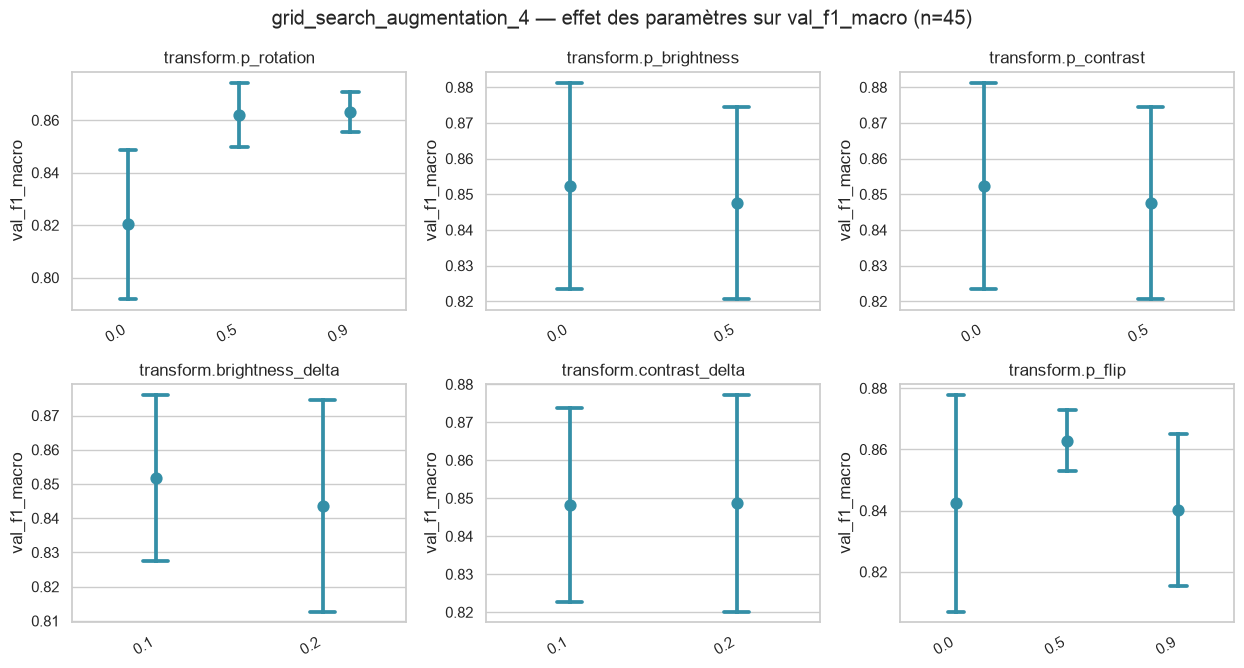

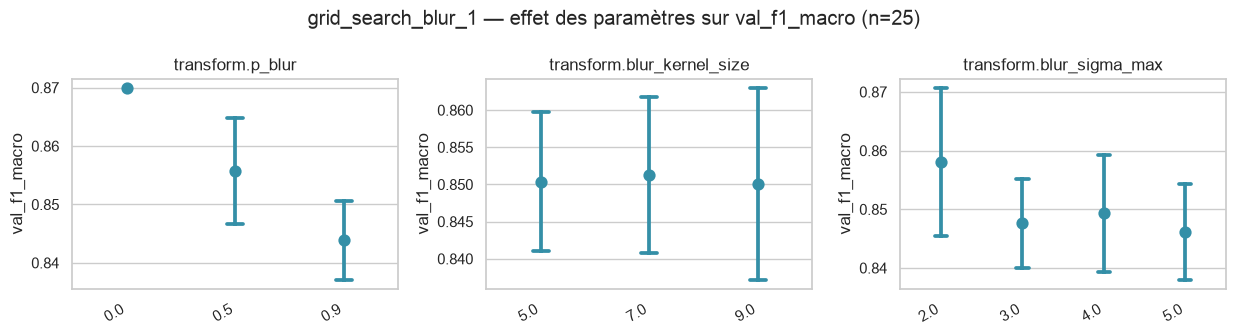

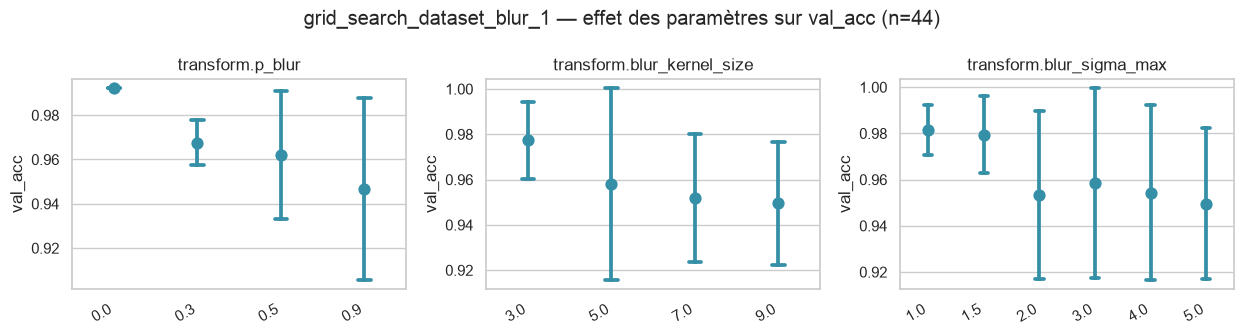

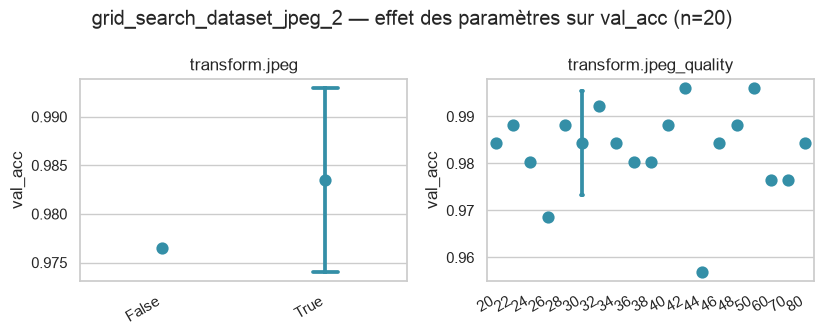

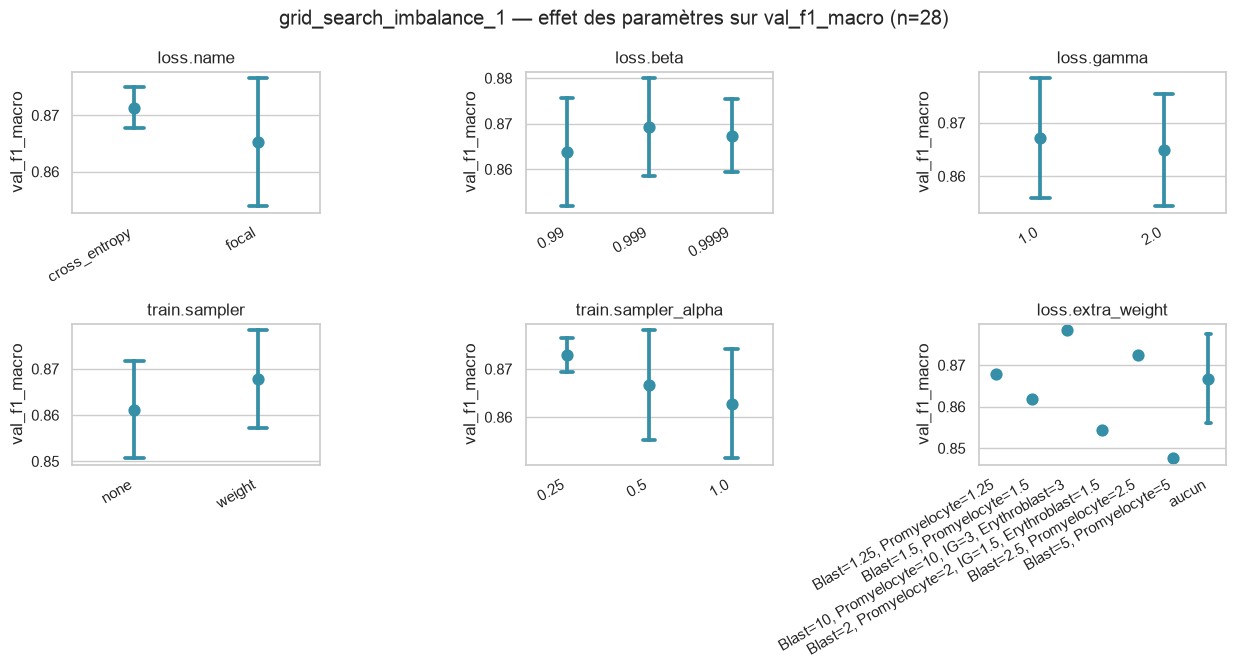

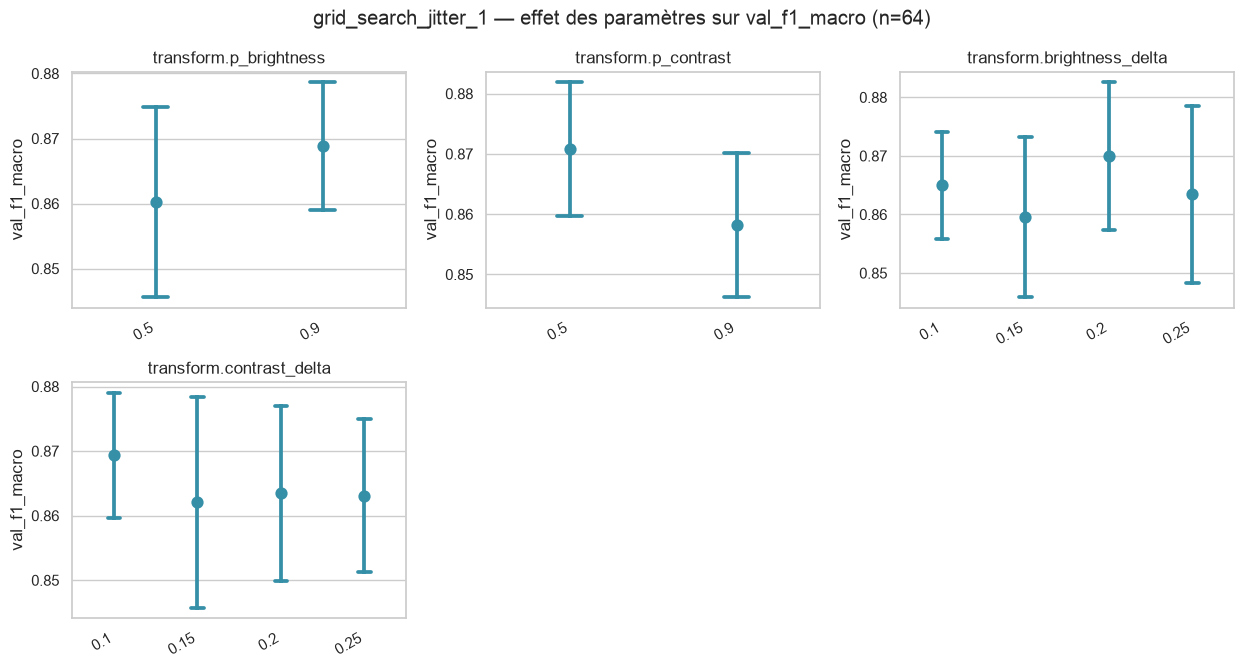

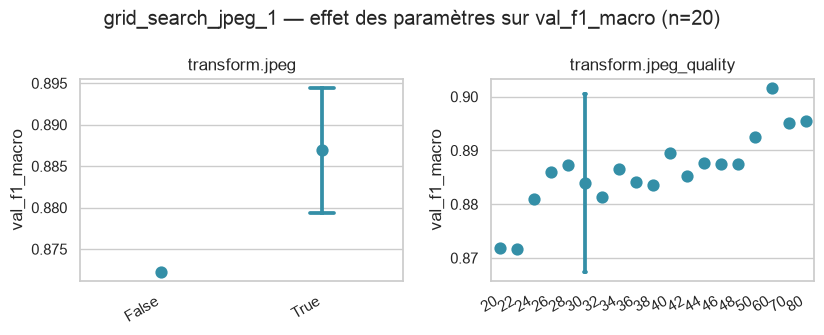

In [110]:
sns.set_theme(style="whitegrid")
grid_accent = sns.color_palette("mako", 6)[3]


def _sort_key(v):
    if v == "NA":
        return (2, 0.0, "")
    if isinstance(v, bool | int | float):
        return (0, float(v), "")
    return (1, 0.0, str(v))


def plot_param_effects(name: str):
    """Point plot (moyenne +/- écart-type) de la métrique par valeur, un panneau
    par paramètre varié dans ce grid search.
    """
    g = grid_df[grid_df["name"] == name]
    task = g["task"].iloc[0]
    metric = METRIC_BY_TASK[task]
    g, params = merge_extra_weight_columns(g, varying_params(g))
    if not params:
        print(f"{name} : aucun paramètre varié détecté.")
        return None

    ncols = min(3, len(params))
    nrows = -(-len(params) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows), squeeze=False)

    for ax, col in zip(axes.flat, params, strict=False):
        plot_data = g[[col, metric]].copy()
        plot_data[col] = plot_data[col].apply(lambda v: "NA" if pd.isna(v) else v)
        order = sorted(plot_data[col].unique(), key=_sort_key)
        sns.pointplot(
            data=plot_data,
            x=col,
            y=metric,
            order=order,
            color=grid_accent,
            errorbar="sd",
            capsize=0.15,
            linestyle="none",
            ax=ax,
        )
        ax.set_title(col)
        ax.set_xlabel(None)
        ax.tick_params(axis="x", rotation=30)
        for label in ax.get_xticklabels():
            label.set_ha("right")

    for ax in axes.flat[len(params) :]:
        ax.set_visible(False)

    fig.suptitle(f"{name} — effet des paramètres sur {metric} (n={len(g)})")
    fig.tight_layout()
    return fig


for grid_name in sorted(selected_names):
    plot_param_effects(grid_name)
    plt.show()